## 1. Data Exploration (EDA)

In [14]:
from pathlib import Path
base_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection")
print("Top level contents",[p.name for p in base_dir.iterdir()])

Top level contents ['sample_submission.csv', 'train_images', 'supplemental_masks', 'train_masks', 'supplemental_images', 'test_images']


In [15]:
auth_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_images/authentic")
forged_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_images/forged")
mask_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_masks")

In [16]:
auth_files=sorted(auth_dir.glob("*"))
forged_files=sorted(forged_dir.glob("*"))
masked_files=sorted(train_mask_dir.glob("*.npy"))
print(f"Authentic images:{len(auth_files)}")
print(f"Forged images:{len(forged_files)}")
print(f"Masked files(.npy):{len(masked_files)}")
print(f"Sample forged image: {forged_files[0].name}")
print(f"Sample masked image: {masked_files[0].name}")

Authentic images:2377
Forged images:2751
Masked files(.npy):2751
Sample forged image: 10.png
Sample masked image: 10.npy


Image shape: (512, 648, 3)
Mask Shape (1, 512, 648)
Mask dtype uint8
Unique mask value [0 1]


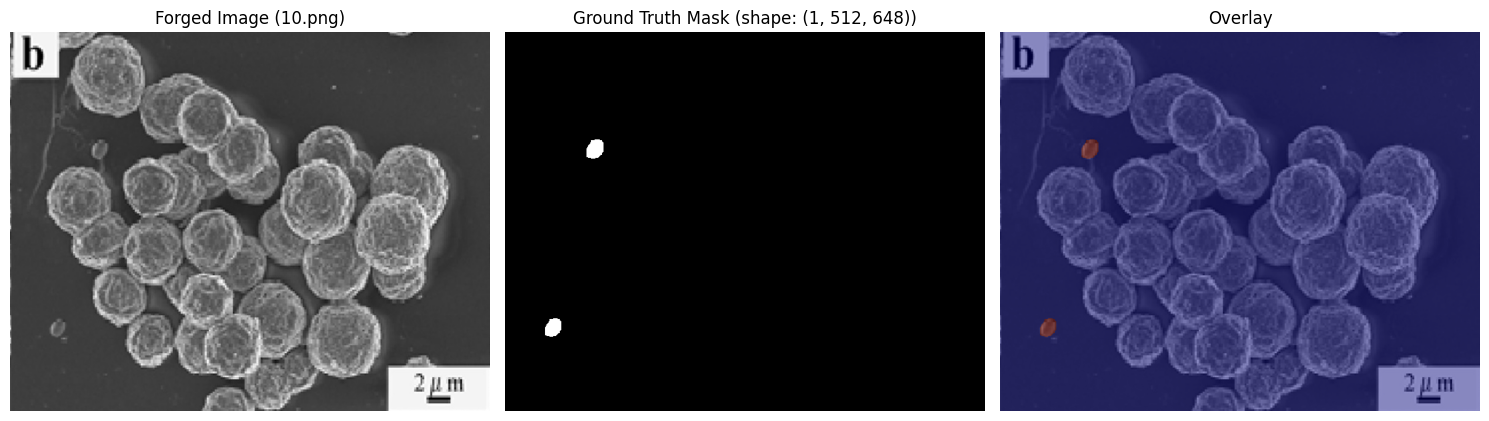

In [22]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
img_path=forged_files[0]
mask_path=mask_dir/f"{img_path.stem}.npy"
img=np.array(Image.open(img_path).convert("RGB"))
mask=np.load(mask_path)
print("Image shape:",img.shape)
print("Mask Shape",mask.shape)
print("Mask dtype",mask.dtype)
print("Unique mask value",np.unique(mask))

mask_2d=mask.max(axis=0) if mask.ndim==3 else mask
fig,axes =plt.subplots(1,3,figsize=(15,5))

axes[0].imshow(img)
axes[0].set_title(f"Forged Image ({img_path.name})")
axes[0].axis("off")

axes[1].imshow(mask_2d,cmap="gray")
axes[1].set_title(f"Ground Truth Mask (shape: {mask.shape})")
axes[1].axis("off")

axes[2].imshow(img) 
axes[2].imshow(mask_2d>0,cmap="jet",alpha=0.45)
axes[2].set_title("Overlay")
axes[2].axis("off")
plt.tight_layout()
plt.show()
